# Results: original and estimated dates

In [1]:
import sys
import tempfile

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
ACTIVE_LIFE_PATH = '../../data/enriched_parquets/individual_active_life.parquet'  # 03_b_active_life, not yet in the database

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Dates of `individual_enriched` and the active life of 03_b_active_life, original (Wikidata) or estimated.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
dates = con.sql('''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.death_date.year AS death_year,
           individual_enriched.birth_date.source AS birth_source,
           individual_enriched.death_date.source AS death_source,
           individual_enriched.birth_date.coarse_label IS NOT NULL OR individual_enriched.death_date.coarse_label IS NOT NULL AS coarse,
           len(individual.floruit_date) > 0 AS floruit,
           active_life.start_of_active_life.source AS active_source,
           active_life.start_of_active_life.year AS active_start_year,
           active_life.end_of_active_life.year AS active_end_year
    FROM individual_enriched
    JOIN individual ON individual.entity.qid = individual_enriched.entity.qid
    LEFT JOIN read_parquet($active_life) AS active_life ON active_life.qid = individual_enriched.entity.qid
''', params={'active_life': ACTIVE_LIFE_PATH}).pl()
assert dates['qid'].is_unique().all()
print(f'{dates.height:,} individuals')
dates.sample(5, seed=42)

13,002,897 individuals


qid,birth_year,death_year,birth_source,death_source,coarse,floruit,active_source,active_start_year,active_end_year
str,i64,i64,str,str,bool,bool,str,i64,i64
"""Q88428089""",null,null,null,null,false,false,null,null,null
"""Q122303749""",null,null,null,null,false,false,null,null,null
"""Q59094413""",null,null,null,null,false,false,null,null,null
"""Q96956693""",null,null,null,null,false,false,null,null,null
"""Q102394987""",null,null,null,null,false,false,null,null,null


## Counts

In [3]:
period = pl.col('active_start_year') < pl.col('active_end_year')
counts = {
    'Original birth date': pl.col('birth_source') == 'wikidata',
    'Estimated birth date': pl.col('birth_source') == 'estimated',
    'Original death date': pl.col('death_source') == 'wikidata',
    'Estimated death date': pl.col('death_source') == 'estimated',
    'Original active life': (pl.col('active_source') == 'dated works and positions') & period,
    'Estimated active life': pl.col('active_source') == 'estimated',
}
results = pl.DataFrame([
    {'dates': name, 'individuals': dates.filter(rule).height, 'share of the database (%)': 100 * dates.filter(rule).height / dates.height}
    for name, rule in counts.items()
])
single_year = dates.filter((pl.col('active_source') == 'dated works and positions') & ~period).height
print(f'{single_year:,} individuals with dated works and positions all in one year: neither an original nor an estimated active life')

197,104 individuals with dated works and positions all in one year: neither an original nor an estimated active life


## Dates added, by what Wikidata gave

In [7]:
def first_match(rules):
    """The name of the first rule an individual matches."""
    expression = pl.lit(None, pl.String)
    for name, rule in reversed(rules.items()):
        expression = pl.when(rule).then(pl.lit(name)).otherwise(expression)
    return expression


wikidata_birth = (pl.col('birth_source') == 'wikidata') & pl.col('birth_year').is_not_null()
wikidata_death = (pl.col('death_source') == 'wikidata') & pl.col('death_year').is_not_null()
single_year = (pl.col('active_source') == 'dated works and positions') & ~period
GROUPS = {
    'Birth and death': wikidata_birth & wikidata_death,
    'Birth only': wikidata_birth,
    'Death only': wikidata_death,
    'Century or millennium only': pl.col('coarse'),
    'No birth or death date': pl.lit(True),
}
by_group = (
    dates.with_columns(first_match(GROUPS).alias('in Wikidata'))
    .group_by('in Wikidata')
    .agg(
        pl.len().alias('individuals'),
        wikidata_birth.sum().alias('birth'),
        (pl.col('birth_source') == 'estimated').sum().alias('estimated birth'),
        wikidata_death.sum().alias('death'),
        (pl.col('death_source') == 'estimated').sum().alias('estimated death'),
        counts['Original active life'].sum().alias('active life'),
        (pl.col('active_source') == 'estimated').sum().alias('estimated active life'),
    )
    .sort(pl.col('in Wikidata').replace_strict(list(GROUPS), list(range(len(GROUPS)))))
)
total = by_group.select(pl.lit('Total').alias('in Wikidata'), pl.exclude('in Wikidata').sum())
by_group = pl.concat([by_group, total])
by_group

in Wikidata,individuals,birth,estimated birth,death,estimated death,active life,estimated active life
str,u32,u32,u32,u32,u32,u32,u32
"""Birth and death""",3209577,3209577,0,3209577,0,321304,2775457
"""Birth only""",4140220,4140220,0,0,404563,381730,1049557
"""Death only""",291556,0,291554,291556,0,15039,275188
"""Century or millennium only""",108029,0,0,0,0,3051,0
"""No birth or death date""",5253515,0,0,0,0,53920,0
"""Total""",13002897,7349797,291554,3501133,404563,775044,4100202


### Table 7: Original and imputed dates, by the life dates recorded in Wikidata

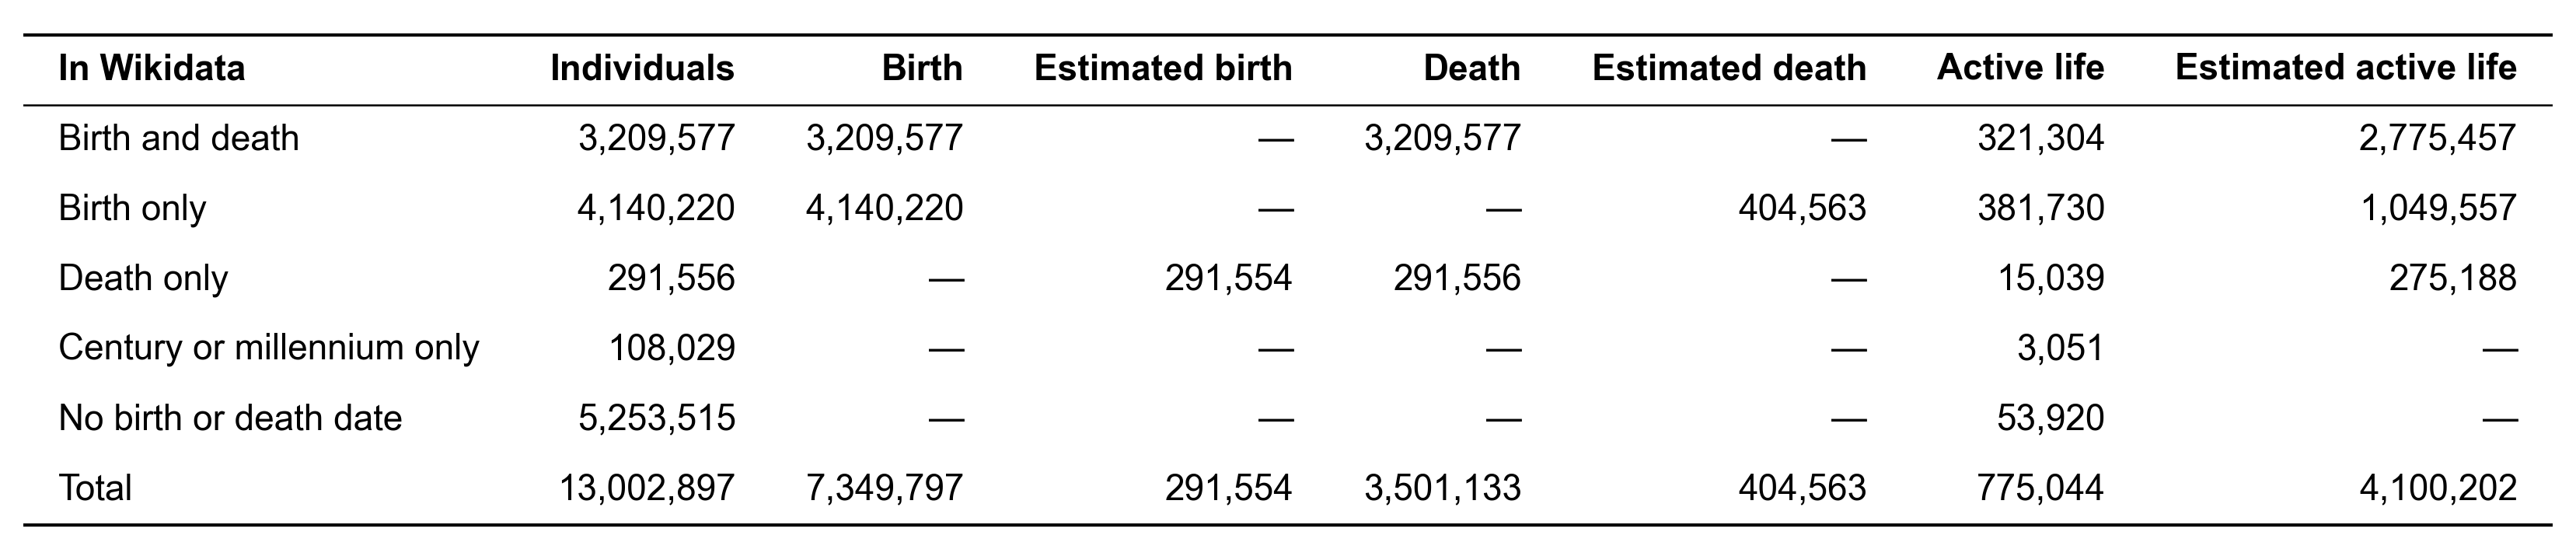

In [8]:
show_table(by_group.with_columns(
    pl.when(pl.col(column) == 0).then(pl.lit('—')).otherwise(pl.col(column).map_elements(lambda v: f'{v:,}', return_dtype=pl.String)).alias(column)
    for column in by_group.columns[1:]
).rename(lambda column: column[0].upper() + column[1:]))  # a dash instead of 0, capitalised column names